# RNN 실습 1: 번역 예제로 순전파 · 역전파

이론 시간의 예제 그대로: **baseball, bat → 야구, 배트**

| 순서 | 내용 | 시간 |
|---|---|---|
| 1 | 순전파: 슬라이드 숫자와 같은지 확인 | 5분 |
| 2 | 역전파: 기울기 보기, 1번 업데이트 | 10분 |
| 3 | 학습 반복: loss·정답 확률 그래프 | 5분 |
| 4 | `nn.RNN` + 옵티마이저로 같은 학습 | 5분 |
| 5 | 기억(W_hh)이 꼭 필요한 경우: bat → 배트? 박쥐? | 5분 |
| 6 | 문제 (코드를 직접 고쳐 보기) | 남는 시간·과제 |

> 맨 아래 **부록**: 스칼라 한 칸 손계산, tanh vs ReLU (선택)

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

LR = 0.5        # 학습률
STEPS = 100     # 업데이트 횟수

## 1. 순전파
- 원-핫: baseball = [1,0,0], bat = [0,1,0], ball = [0,0,1] / 야구 = 0번, 배트 = 1번, 공 = 2번
- 크기: 입력 3, hidden 2, 출력 3
- 시점마다: ① $h = \tanh(W_{xh}x + W_{hh}h_{t-1})$ ② $o = W_{hy}h$ ③ $\hat{y} = \text{softmax}(o)$ ④ loss $= -\log$(정답 칸 확률)

In [2]:
def make_weights():
    """슬라이드와 같은 시작 값. requires_grad=True → 이 값들의 미분을 구하겠다는 표시"""
    W_xh = torch.tensor([[0.5, 0.1, 0.2], [-0.3, 0.4, 0.1]], requires_grad=True)   # (2, 3) 입력 → 기억
    W_hh = torch.tensor([[0.2, -0.1], [0.1, 0.3]], requires_grad=True)             # (2, 2) 기억 → 기억
    W_hy = torch.tensor([[0.6, -0.2], [-0.4, 0.5], [0.1, 0.1]], requires_grad=True) # (3, 2) 기억 → 출력
    return W_xh, W_hh, W_hy

eye = torch.eye(3)
baseball, bat, ball = eye[0], eye[1], eye[2]     # 원-핫 벡터
kor = ["야구", "배트", "공"]

xs = [baseball, bat]          # 입력 순서
targets = [0, 1]              # 정답: 야구, 배트

def forward(W_xh, W_hh, W_hy, xs, targets, show=False):
    h = torch.zeros(W_hh.shape[0])                 # h0 = 0
    total, probs = 0, []
    for t, (x, y) in enumerate(zip(xs, targets), start=1):
        h = torch.tanh(W_xh @ x + W_hh @ h)        # ① 기억
        o = W_hy @ h                               # ② 점수
        p = torch.softmax(o, dim=0)                # ③ 확률
        loss = -torch.log(p[y])                    # ④ 손실
        total = total + loss
        probs.append(p)
        if show:
            print(f"t={t}: h={[round(v, 2) for v in h.tolist()]}  ŷ={[round(v, 2) for v in p.tolist()]}  "
                  f"예측={kor[p.argmax()]}  정답={kor[y]}  loss={loss.item():.2f}")
    return total, probs

W_xh, W_hh, W_hy = make_weights()
loss, _ = forward(W_xh, W_hh, W_hy, xs, targets, show=True)
print(f"전체 loss = {loss.item():.2f}")

t=1: h=[0.46, -0.29]  ŷ=[0.45, 0.23, 0.32]  예측=야구  정답=야구  loss=0.81
t=2: h=[0.22, 0.34]  ŷ=[0.33, 0.34, 0.33]  예측=배트  정답=배트  loss=1.08
전체 loss = 1.89


## 2. 역전파: 세 W의 기울기 구하기
`loss.backward()` 한 줄이 **펼친 그림을 시간 반대로 거슬러 가며(BPTT)** 세 W의 미분을 모두 구함.
- $W_{hy}$: 출력에서 바로 / $W_{xh}$, $W_{hh}$: h를 거쳐서, $W_{hh}$는 h₂ → h₁로 시간을 거슬러
- 같은 W를 두 시점에서 썼으므로 **두 시점의 미분이 자동으로 더해짐**

In [3]:
loss.backward()
print("W_xh 기울기\n", W_xh.grad.round(decimals=3))
print("W_hh 기울기\n", W_hh.grad.round(decimals=3))
print("W_hy 기울기\n", W_hy.grad.round(decimals=3))

W_xh 기울기
 tensor([[-0.2590,  0.4730,  0.0000],
        [ 0.1050, -0.3210,  0.0000]])
W_hh 기울기
 tensor([[ 0.2180, -0.1380],
        [-0.1480,  0.0930]])
W_hy 기울기
 tensor([[-0.1840,  0.2750],
        [-0.0380, -0.2940],
        [ 0.2220,  0.0190]])


기울기가 **양수**인 칸은 값을 키우면 loss가 커짐 → 줄여야 함, **음수**인 칸은 키워야 함.
경사하강법: $W \leftarrow W - \text{학습률} \times \text{기울기}$ 를 세 W에 모두 적용.

In [4]:
with torch.no_grad():                       # 업데이트 계산은 미분 기록 안 함
    for W in (W_xh, W_hh, W_hy):
        W -= LR * W.grad
        W.grad = None                           # 다음 계산을 위해 기울기 비우기

loss, _ = forward(W_xh, W_hh, W_hy, xs, targets, show=True)
print(f"1번 업데이트 후 전체 loss = {loss.item():.2f}   (처음 1.89)")

t=1: h=[0.56, -0.34]  ŷ=[0.51, 0.2, 0.3]  예측=야구  정답=야구  loss=0.68
t=2: h=[-0.07, 0.52]  ŷ=[0.24, 0.44, 0.32]  예측=배트  정답=배트  loss=0.83
1번 업데이트 후 전체 loss = 1.51   (처음 1.89)


## 3. 학습 반복
순전파 → loss → 역전파 → 업데이트를 `STEPS`번 반복.

  0번 업데이트: loss 1.888 | 정답 확률 [0.45, 0.34]
  1번 업데이트: loss 1.508 | 정답 확률 [0.51, 0.44]
 10번 업데이트: loss 0.202 | 정답 확률 [0.9, 0.91]
100번 업데이트: loss 0.020 | 정답 확률 [0.99, 0.99]


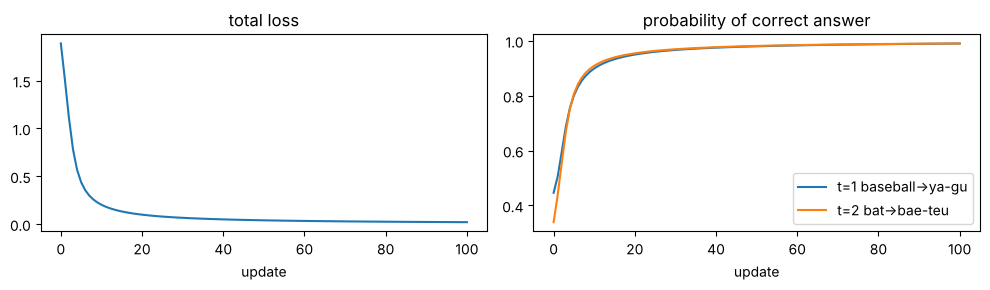

In [5]:
def train(xs, targets, lr=LR, steps=STEPS, weights=None):
    W_xh, W_hh, W_hy = weights if weights else make_weights()
    losses, correct = [], []
    for step in range(steps + 1):
        loss, probs = forward(W_xh, W_hh, W_hy, xs, targets)
        losses.append(loss.item())
        correct.append([p[y].item() for p, y in zip(probs, targets)])   # 시점마다 정답 칸 확률
        if step == steps:
            break
        loss.backward()
        with torch.no_grad():
            for W in (W_xh, W_hh, W_hy):
                if W.requires_grad:
                    W -= lr * W.grad
                    W.grad = None
    return losses, correct

losses, correct = train(xs, targets)
for s in [0, 1, 10, 100]:
    print(f"{s:3d}번 업데이트: loss {losses[s]:.3f} | 정답 확률 {[round(c, 2) for c in correct[s]]}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.plot(losses); ax1.set_title("total loss"); ax1.set_xlabel("update")
ax2.plot([c[0] for c in correct], label="t=1 baseball->ya-gu")
ax2.plot([c[1] for c in correct], label="t=2 bat->bae-teu")
ax2.set_title("probability of correct answer"); ax2.set_xlabel("update"); ax2.legend()
plt.tight_layout(); plt.show()

## 4. `nn.RNN` + 옵티마이저로 같은 학습
직접 쓴 순전파·업데이트를 PyTorch 부품으로 바꾸면 아래와 같음. 시작 w가 같으면 결과도 같음.

| 직접 쓴 코드 | PyTorch |
|---|---|
| `torch.tanh(W_xh @ x + W_hh @ h)` 반복 | `nn.RNN(3, 2, bias=False)` |
| `W_hy @ h` | `nn.Linear(2, 3, bias=False)` |
| softmax + −log | `nn.CrossEntropyLoss()` |
| `W -= LR * W.grad` | `optimizer.step()` (SGD) |

In [6]:
W_xh0, W_hh0, W_hy0 = make_weights()
rnn = nn.RNN(input_size=3, hidden_size=2, bias=False, batch_first=True)
fc = nn.Linear(2, 3, bias=False)
with torch.no_grad():
    rnn.weight_ih_l0[:] = W_xh0
    rnn.weight_hh_l0[:] = W_hh0
    fc.weight[:] = W_hy0

loss_fn = nn.CrossEntropyLoss(reduction="sum")         # 시점별 loss를 더함 (위와 같게)
optimizer = torch.optim.SGD(list(rnn.parameters()) + list(fc.parameters()), lr=LR)
X = torch.stack(xs).unsqueeze(0)                       # (배치 1, 길이 2, 입력 3)
Y = torch.tensor(targets)

for step in range(STEPS + 1):
    out, _ = rnn(X)                                    # 모든 시점의 h
    loss = loss_fn(fc(out).squeeze(0), Y)              # many-to-many: 모든 시점에 fc
    if step in (0, 1, 10, 100):
        print(f"{step:3d}번 업데이트: loss {loss.item():.3f}")
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  0번 업데이트: loss 1.888
  1번 업데이트: loss 1.508
 10번 업데이트: loss 0.202
100번 업데이트: loss 0.020


## 5. 기억(W_hh)이 꼭 필요한 경우
같은 **bat**이라도 앞 단어에 따라 번역이 달라지는 문장 2개를 학습.
- [baseball, bat] → [야구, **배트**]
- [cave, bat] → [동굴, **박쥐**]

두 번째 시점에 들어오는 단어는 둘 다 bat. **앞 단어를 기억하는 $W_{hh}$가 없으면** 배트인지 박쥐인지 구별할 수 없음.

In [7]:
in_words = ["baseball", "bat", "cave"]
out_words = ["야구", "배트", "동굴", "박쥐"]
e = torch.eye(3)
data = [([e[0], e[1]], [0, 1]),        # baseball bat → 야구 배트
        ([e[2], e[1]], [2, 3])]        # cave bat     → 동굴 박쥐

def train_context(use_memory, steps=300, lr=0.5):
    torch.manual_seed(0)
    W_xh = (torch.randn(2, 3) * 0.5).requires_grad_(True)
    W_hh = (torch.randn(2, 2) * 0.5).requires_grad_(True)
    W_hy = (torch.randn(4, 2) * 0.5).requires_grad_(True)
    if not use_memory:
        W_hh = torch.zeros(2, 2)                      # 기억 연결을 끊음 (학습도 안 함)
    params = [W for W in (W_xh, W_hh, W_hy) if W.requires_grad]
    for step in range(steps + 1):
        total, result = 0, []
        for xs_, ys_ in data:
            h = torch.zeros(2)
            for x, y in zip(xs_, ys_):
                h = torch.tanh(W_xh @ x + W_hh @ h)
                p = torch.softmax(W_hy @ h, dim=0)
                total = total - torch.log(p[y])
                result.append(f"{out_words[y]} {p[y].item():.2f}")
        if step == steps:
            print(("W_hh 사용 " if use_memory else "W_hh = 0  ") + f"loss {total.item():.3f} | 정답 확률: " + ", ".join(result))
            break
        total.backward()
        with torch.no_grad():
            for W in params:
                W -= lr * W.grad
                W.grad = None

train_context(use_memory=True)
train_context(use_memory=False)

W_hh 사용 loss 0.014 | 정답 확률: 야구 1.00, 배트 1.00, 동굴 1.00, 박쥐 1.00
W_hh = 0  loss 1.396 | 정답 확률: 야구 1.00, 배트 0.50, 동굴 1.00, 박쥐 0.50


- **W_hh 사용**: 네 칸 모두 정답 확률 1.00 → 앞 단어(baseball / cave)를 기억해서 bat을 다르게 번역
- **W_hh = 0**: 배트·박쥐가 0.50에서 멈춤 → 기억이 없으면 bat만 보고는 반반으로 찍을 수밖에 없음
- 이것이 RNN이 이전 기억 $h_{t-1}$을 다음 시점으로 넘기는 이유

## 6. 문제: 코드를 직접 고쳐 보기
1. 맨 위 `LR`을 0.05, 2.0으로 바꾸고 3번 셀을 다시 실행하기. 10번째·100번째 loss를 0.5일 때와 비교하기.
2. 세 번째 단어를 추가해서 **[baseball, bat, ball] → [야구, 배트, 공]**을 학습시키기. 어디를 고쳐야 할까?
3. 입력 순서를 **[bat, baseball] → [배트, 야구]**로 바꾸면 학습이 될까?
4. hidden 크기를 2 → 4로 바꾸기. `make_weights`의 세 행렬 모양은 각각 어떻게 바뀌어야 할까? (숫자는 `torch.randn(...) * 0.5`로 랜덤)
5. 기본 예제(baseball, bat)에서 `W_hh`를 0으로 고정하고 학습하면? 5번 실험(배트·박쥐)과 결과가 다른 이유는?
6. `correct`를 이용해 시점별 정답 확률이 0, 1, 3, 5, 10번째 업데이트에서 어떻게 변하는지 출력하기. 어느 시점이 먼저 좋아질까?
7. (도전) 5번 실험에 [cave, ball] → [동굴, 공]을 추가해 보기. `out_words`, `W_hy` 모양, `data`를 어떻게 바꿔야 할까?

<details><summary>정답 보기</summary>

1. (10번째 / 100번째 loss) LR 0.05: 1.480 / 0.211, LR 0.5: 0.202 / 0.020, LR 2.0: 0.045 / 0.005. 작으면 느리고, 이 예제에서는 2.0도 잘 됨. 실제 데이터에서 너무 크면 발산할 수 있음.
2. `xs = [baseball, bat, ball]`, `targets = [0, 1, 2]`만 바꾸면 됨 (W 모양은 그대로: 단어 수 3개 그대로). 실행 결과 예: loss 2.995 → 10번째 0.495 → 100번째 0.024.
3. 됨. `xs = [bat, baseball]`, `targets = [1, 0]`. loss 1.855 → 100번째 0.020.
4. W_xh (4, 3), W_hh (4, 4), W_hy (3, 4). 예:
   ```python
   torch.manual_seed(0)
   W_xh = (torch.randn(4, 3) * 0.5).requires_grad_(True)
   W_hh = (torch.randn(4, 4) * 0.5).requires_grad_(True)
   W_hy = (torch.randn(3, 4) * 0.5).requires_grad_(True)
   ```
   실행 결과 예: loss 2.80 → 100번째 0.009.
5. `W_hh = torch.zeros(2, 2)` (requires_grad 없이). 그래도 잘 학습됨 (1.818 → 0.020). 이 예제는 단어마다 번역이 하나뿐이라 앞 단어를 기억할 필요가 없음. 5번처럼 **같은 단어가 문맥에 따라 다르게 번역**될 때 기억이 필요함.
6. 예: `for s in [0, 1, 3, 5, 10]: print(s, [round(c, 2) for c in correct[s]])`. t=1(야구)은 0.45에서 출발해 먼저 높아지고, t=2(배트)는 0.34에서 늦게 출발하지만 5번째쯤 비슷해짐.
7. `out_words`에 "공" 추가(5개), `W_hy = torch.randn(5, 2) * 0.5`, `data`에 `([e[2], e[1] 대신 ball 원-핫], ...)` 추가. 입력 단어도 4개가 되면 `e = torch.eye(4)`, `W_xh = torch.randn(2, 4)`로 바뀜.
</details>

---
## 부록: 이론 시간의 다른 계산 확인 (선택)

### A. 스칼라 RNN 한 칸 계산
$$h_t = \tanh(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b)$$
- $x_t$: 지금 들어온 값, $h_{t-1}$: 직전까지의 기억
- 모든 시점에서 **같은 $W_{xh}, W_{hh}, b$를 재사용**

예제: $W_{xh}=0.5,\ W_{hh}=0.8,\ b=0.1,\ h_0=0$, 입력 $x = [1.0,\ 0.5,\ -1.0]$

In [8]:
W_xh, W_hh, b = 0.5, 0.8, 0.1
xs = [1.0, 0.5, -1.0]

h = 0.0                                   # h0 = 0 (아직 기억 없음)
for t, x in enumerate(xs, start=1):
    z = W_xh * x + W_hh * h + b           # 가중합 = 지금 입력 + 이전 기억
    print(f"t={t}: z = {W_xh}×{x} + {W_hh}×{h:.3f} + {b} = {z:.3f}", end="  ")
    h = torch.tanh(torch.tensor(z)).item()   # tanh로 -1 ~ 1 사이로
    print(f"→ h{t} = tanh({z:.3f}) = {h:.3f}")

t=1: z = 0.5×1.0 + 0.8×0.000 + 0.1 = 0.600  → h1 = tanh(0.600) = 0.537
t=2: z = 0.5×0.5 + 0.8×0.537 + 0.1 = 0.780  → h2 = tanh(0.780) = 0.652
t=3: z = 0.5×-1.0 + 0.8×0.652 + 0.1 = 0.122  → h3 = tanh(0.122) = 0.121


같은 값을 `nn.RNN`의 w에 직접 넣어서 결과가 똑같은지 확인.

In [9]:
rnn = nn.RNN(input_size=1, hidden_size=1, batch_first=True)
with torch.no_grad():
    rnn.weight_ih_l0[:] = W_xh       # W_xh (입력 → 기억)
    rnn.weight_hh_l0[:] = W_hh       # W_hh (기억 → 기억)
    rnn.bias_ih_l0[:] = b            # PyTorch는 b를 2개로 나눠 가짐
    rnn.bias_hh_l0[:] = 0.0

x = torch.tensor(xs).reshape(1, 3, 1)    # (배치 1, 길이 3, 입력 1개)
out, h_n = rnn(x)
print("시점마다 h:", [round(v, 3) for v in out.squeeze().tolist()])
print("마지막 h :", round(h_n.item(), 3))

시점마다 h: [0.537, 0.652, 0.121]
마지막 h : 0.121


### B. tanh 대신 ReLU를 쓰면?
`nn.RNN`은 `nonlinearity="relu"`로 활성화 함수를 바꿀 수 있음.
$W_{xh}=0.5,\ W_{hh}=1.2$로 두고 입력 1을 20번 넣어서 기억 $h$가 어떻게 변하는지 비교.

In [10]:
for act in ["tanh", "relu"]:
    rnn = nn.RNN(input_size=1, hidden_size=1, nonlinearity=act, batch_first=True)
    with torch.no_grad():
        rnn.weight_ih_l0[:] = 0.5
        rnn.weight_hh_l0[:] = 1.2        # 1보다 큰 W_hh
        rnn.bias_ih_l0[:] = 0.0
        rnn.bias_hh_l0[:] = 0.0
    out, _ = rnn(torch.ones(1, 20, 1))   # 입력 1을 20번
    h = out.squeeze().tolist()
    print(f"{act:5s} t=1: {h[0]:.2f}  t=5: {h[4]:.2f}  t=10: {h[9]:.2f}  t=20: {h[19]:.2f}")

tanh  t=1: 0.46  t=5: 0.92  t=10: 0.92  t=20: 0.92
relu  t=1: 0.50  t=5: 3.72  t=10: 12.98  t=20: 93.34


- **ReLU**: 양수를 그대로 통과 → 같은 $W_{hh}=1.2$가 매 시점 곱해져 기억이 계속 커짐 (**발산**)
- **tanh**: 결과가 −1 ~ 1에 묶여 반복해도 안정
- 그래서 기본 RNN(Vanilla RNN)은 tanh를 사용. 대신 tanh 미분이 작아서 먼 과거를 잘 못 배우는 **장기 의존성 문제**가 생김 → 2일차 LSTM